# Heston implied-vol smile

Price calls for $K = 70, 72, \dots, 130$ at $T = 1$ with `heston.pricer.call`, invert to Black-Scholes implied vols, and plot IV vs $K$.

In [2]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # so `import heston` works from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from heston.params import HestonParams
from heston.pricer import call
from heston.bs import implied_vol

%matplotlib inline

## Helpers

In [3]:
def strike_grid(params, S0=100.0, r=0.03, T=1.0, q=0.0, n_sd=2.5, n=31):
    """Strikes F*exp(k), k evenly spaced over +/- n_sd * sigma * sqrt(T).

    Scales with maturity so short-dated wings don't fall below the pricer's accuracy.
    sigma uses max(v0, vbar) as a rough vol level.
    """
    F = S0 * np.exp((r - q) * T)
    w = n_sd * np.sqrt(max(params.v0, params.vbar) * T)
    return F * np.exp(np.linspace(-w, w, n))

# fixed series colors, assigned in order (never cycled)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]


def heston_smile(params, S0=100.0, r=0.03, T=1.0, q=0.0, strikes=None):
    """Heston call prices and BS implied vols across strikes (default: strike_grid)."""
    if strikes is None:
        strikes = strike_grid(params, S0, r, T, q)
    rows = []
    for K in strikes:
        price = call(S0, K, r, T, params, q)
        rows.append({"K": K, "price": price, "iv": implied_vol(price, S0, K, r, T, q)})
    return pd.DataFrame(rows)


def plot_smile(smiles, title="Heston implied vol smile", S0=None):
    """smiles: a DataFrame from heston_smile, or a dict {label: DataFrame}."""
    if isinstance(smiles, pd.DataFrame):
        smiles = {None: smiles}
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for color, (label, df) in zip(COLORS, smiles.items()):
        ax.plot(df["K"], 100 * df["iv"], color=color, lw=2,
                marker="o", ms=4, label=label)
    if S0 is not None:
        ax.axvline(S0, color="0.6", lw=1, ls="--")
    ax.set_xlabel("Strike K")
    ax.set_ylabel("Implied vol (%)")
    ax.set_title(title, loc="left")
    ax.grid(True, color="0.9", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if len(smiles) > 1:
        ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.show()
    return ax

## Parameters (change these)

Edit the next code cell, then re-run it and the plot cell below it.
Strikes default to $F e^{\pm 2.5\,\sigma\sqrt{T}}$ so they scale with `T`. To force a fixed grid, pass `strikes=np.arange(70, 131, 2.0)` to `heston_smile`.

- `S0, r, T, q`: spot, rate, maturity, dividend yield
- `HestonParams(v0, kappa, vbar, eta, rho)`: the Heston params for the single smile

In [17]:
S0, r, T, q = 100.0, 0.03, 0.1, 0.0

params = HestonParams(v0=0.04, kappa=2.0, vbar=0.04, eta=0.5, rho=-0.7)
print(params, "| Feller ok:", params.feller_ok())

HestonParams(v0=0.04, kappa=2.0, vbar=0.04, eta=0.5, rho=-0.7) | Feller ok: False


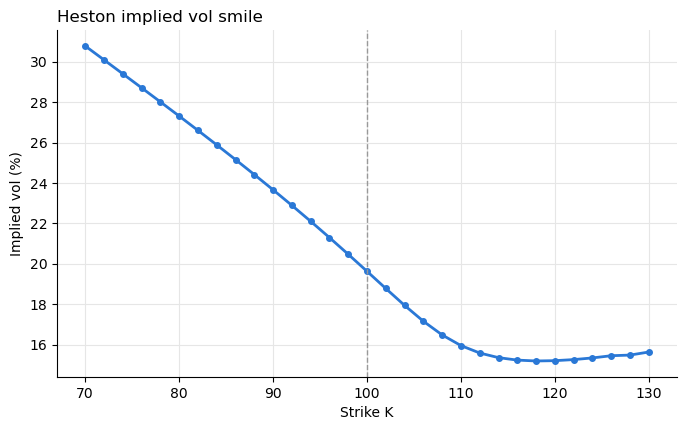

,K,price,iv
0,70.0,30.209900,0.307821
1,72.0,28.216179,0.300942
2,74.0,26.222803,0.294046
3,76.0,24.230134,0.287121
4,78.0,22.238869,0.280156


In [18]:
smile = heston_smile(params, S0, r, T, q)
plot_smile(smile, S0=S0)
smile.head()

## Compare: vary one parameter (change these)

Each cell below holds four params fixed in `base` and loops over one.

- To change the fixed values, edit `base`.
- To change the values compared, edit the list (`rhos` or `etas`).
- The eta cell uses `rho = 0`. With `rho != 0`, eta also steepens the skew, which hides its own effect (curvature).
- To sweep a different param (e.g. `kappa`), take it out of `base`, put `rho` back in, and loop over a `kappas` list instead.

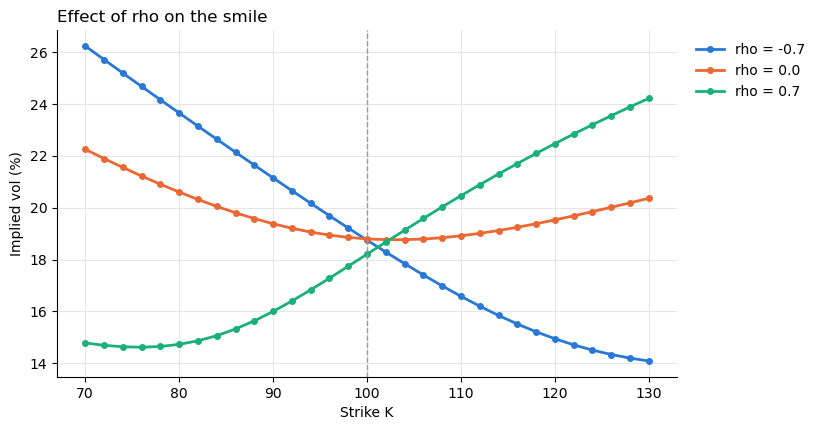

In [12]:
base = dict(v0=0.04, kappa=2.0, vbar=0.04, eta=0.5)
rhos = [-0.7, 0.0, 0.7]

smiles = {f"rho = {rho}": heston_smile(HestonParams(**base, rho=rho), S0, r, T, q) for rho in rhos}
plot_smile(smiles, title="Effect of rho on the smile", S0=S0);

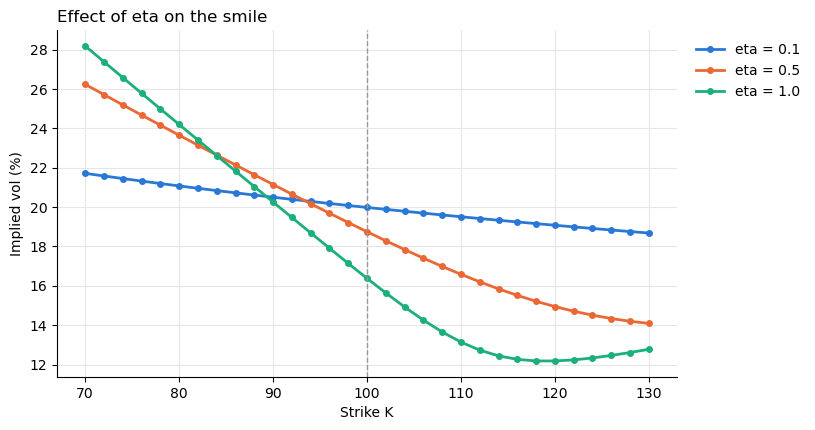

In [7]:
base = dict(v0=0.04, kappa=2.0, vbar=0.04, rho=0.0)  # rho = 0 isolates eta's effect (curvature)
etas = [0.1, 0.5, 1.0]

smiles = {f"eta = {eta}": heston_smile(HestonParams(**base, eta=eta), S0, r, T, q) for eta in etas}
plot_smile(smiles, title="Effect of eta on the smile", S0=S0);